In [12]:
import numpy as np
import pandas as pd
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns

In [13]:
data = {
    'Height': [170, 165, 180, 175, 160, 172, 168, 177, 162, 158],
    'Weight': [65, 59, 75, 68, 55, 70, 62, 74, 58, 54],
    'Age': [30, 25, 35, 28, 22, 32, 27, 33, 24, 21],
    'Gender': [1, 0, 1, 1, 0, 1, 0, 1, 0, 0]  # 1 = Male, 0 = Female
}
df = pd.DataFrame(data)
print(df)

   Height  Weight  Age  Gender
0     170      65   30       1
1     165      59   25       0
2     180      75   35       1
3     175      68   28       1
4     160      55   22       0
5     172      70   32       1
6     168      62   27       0
7     177      74   33       1
8     162      58   24       0
9     158      54   21       0


In [17]:
X = df.drop('Gender', axis=1)
y = df['Gender']




In [18]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.3,
    random_state=42
)

print("\nTraining samples:", len(X_train))
print("Testing samples:", len(X_test))


Training samples: 7
Testing samples: 3


In [19]:
scaler = StandardScaler()

# FIT only on training data
X_train_scaled = scaler.fit_transform(X_train)

# Only TRANSFORM test data
X_test_scaled = scaler.transform(X_test)


In [20]:
pca = PCA(n_components=2)

# FIT PCA only on training data
X_train_pca = pca.fit_transform(X_train_scaled)

# Transform test data using the same PCA
X_test_pca = pca.transform(X_test_scaled)


In [21]:
print("\nPCA Components:")
print(pca.components_)

print("\nExplained Variance Ratio:")
print(pca.explained_variance_ratio_)

print("\nTotal Variance Retained:")
print(pca.explained_variance_ratio_.sum())


print("\nTraining data after PCA:")
print(X_train_pca)

print("\nTest data after PCA:")
print(X_test_pca)



PCA Components:
[[ 0.57725757  0.58068943  0.57408491]
 [-0.58436472 -0.19728157  0.78714538]]

Explained Variance Ratio:
[0.9811625  0.01584247]

Total Variance Retained:
0.9970049709266807

Training data after PCA:
[[ 0.27990011  0.29644621]
 [ 1.83165539  0.02774644]
 [ 2.36707489  0.10156665]
 [-2.50550708  0.01694631]
 [-2.16308985  0.00345668]
 [ 0.63972925 -0.48182463]
 [-0.4497627   0.03566235]]

Test data after PCA:
[[-1.5520321   0.10161751]
 [-1.13521767  0.0128147 ]
 [ 1.04099332  0.34363448]]


In [22]:
model = LogisticRegression()

model.fit(X_train_pca, y_train)


LogisticRegression()

In [23]:
y_pred = model.predict(X_test_pca)

print("\nActual values:")
print(y_test.values)

print("\nPredicted values:")
print(y_pred)




Actual values:
[0 0 1]

Predicted values:
[0 0 1]


In [28]:
from sklearn.metrics import accuracy_score, confusion_matrix, ConfusionMatrixDisplay
accuracy = accuracy_score(y_test, y_pred)
print("\nAccuracy:", accuracy)



Accuracy: 1.0



Confusion Matrix:
[[2 0]
 [0 1]]


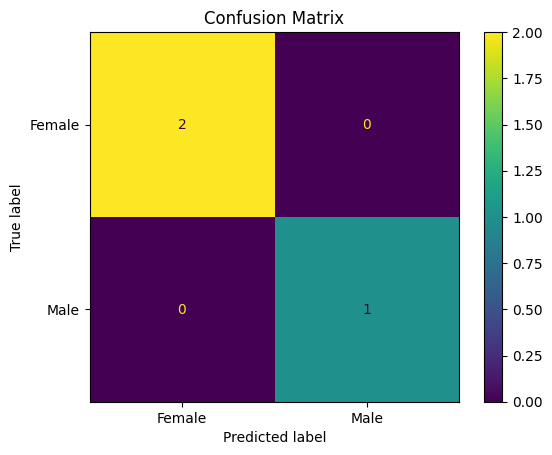

In [29]:
cm = confusion_matrix(y_test, y_pred)

print("\nConfusion Matrix:")
print(cm)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=['Female', 'Male']
)

disp.plot()
plt.title("Confusion Matrix")
plt.show()

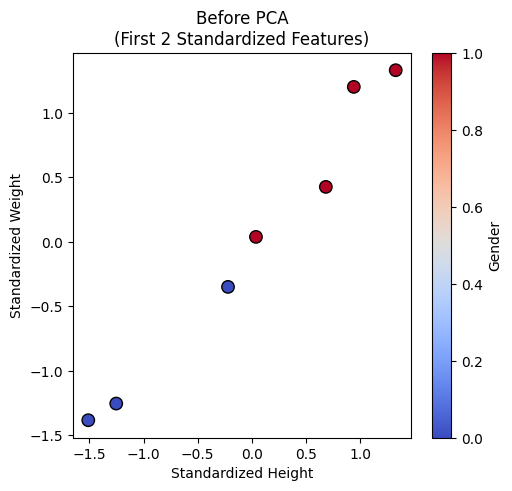

In [30]:

plt.figure(figsize=(12, 5))


# ---------- BEFORE PCA ----------

plt.subplot(1, 2, 1)

plt.scatter(
    X_train_scaled[:, 0],
    X_train_scaled[:, 1],
    c=y_train,
    cmap='coolwarm',
    edgecolor='k',
    s=80
)

plt.xlabel("Standardized Height")
plt.ylabel("Standardized Weight")

plt.title("Before PCA\n(First 2 Standardized Features)")

plt.colorbar(label="Gender")


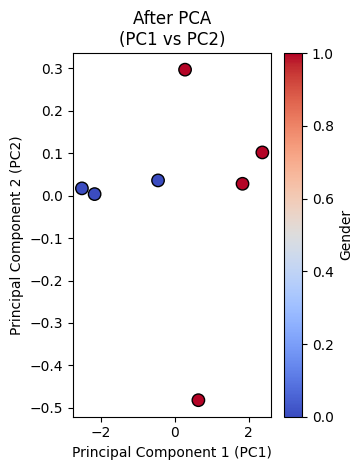

In [32]:

plt.subplot(1, 2, 2)

plt.scatter(
    X_train_pca[:, 0],
    X_train_pca[:, 1],
    c=y_train,
    cmap='coolwarm',
    edgecolor='k',
    s=80
)

plt.xlabel("Principal Component 1 (PC1)")
plt.ylabel("Principal Component 2 (PC2)")

plt.title("After PCA\n(PC1 vs PC2)")

plt.colorbar(label="Gender")


plt.tight_layout()
plt.show()